In [1]:
import pandas as pd
import os


os.chdir("../")

In [2]:
data = pd.read_csv('data/tweets.csv')
data.rename(columns={"tweet_text": "text"}, inplace=True)
data.drop_duplicates(subset=['text'], inplace=True)
label = "cyberbullying_type"
text = "text"
data[label].value_counts()

cyberbullying_type
religion               7995
age                    7992
ethnicity              7952
not_cyberbullying      7937
gender                 7898
other_cyberbullying    6243
Name: count, dtype: int64

### pos-tagging (spacy)

In [3]:
import re
import spacy
from tqdm import tqdm

def clean(text):
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'\brt\b', ' ', text, flags=re.I)
    text = re.sub(r'#', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

nlp = spacy.load('en_core_web_sm')

sample = data.groupby(label, group_keys=False).sample(1500, random_state=42).reset_index(drop=True)
docs = list(tqdm(nlp.pipe(sample[text].apply(clean), batch_size=256), total=len(sample)))
docs[0].text, [(t.text, t.pos_) for t in docs[0]]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 1/9000 [00:00<2:00:24,  1.25it/s]

  3%|▎         | 257/9000 [00:01<00:44, 197.25it/s]

  6%|▌         | 513/9000 [00:02<00:31, 266.29it/s]

  9%|▊         | 769/9000 [00:02<00:27, 301.05it/s]

...

 94%|█████████▍| 8449/9000 [00:18<00:01, 370.79it/s]

 97%|█████████▋| 8705/9000 [00:19<00:00, 359.86it/s]

100%|█████████▉| 8961/9000 [00:19<00:00, 479.44it/s]

100%|██████████| 9000/9000 [00:19<00:00, 457.27it/s]

('Every single one is a girl that would have bullied me in high school.',
 [('Every', 'DET'),
  ('single', 'ADJ'),
  ('one', 'NOUN'),
  ('is', 'AUX'),
  ('a', 'DET'),
  ('girl', 'NOUN'),
  ('that', 'PRON'),
  ('would', 'AUX'),
  ('have', 'AUX'),
  ('bullied', 'VERB'),
  ('me', 'PRON'),
  ('in', 'ADP'),
  ('high', 'ADJ'),
  ('school', 'NOUN'),
  ('.', 'PUNCT')])

### POS distribution

[('NOUN', 40719),
 ('VERB', 29735),
 ('PRON', 28005),
 ('ADP', 18092),
 ('ADJ', 17291),
 ('PROPN', 16984),
 ('AUX', 15661),
 ('DET', 14224),
 ('ADV', 10034),
 ('CCONJ', 6790)]

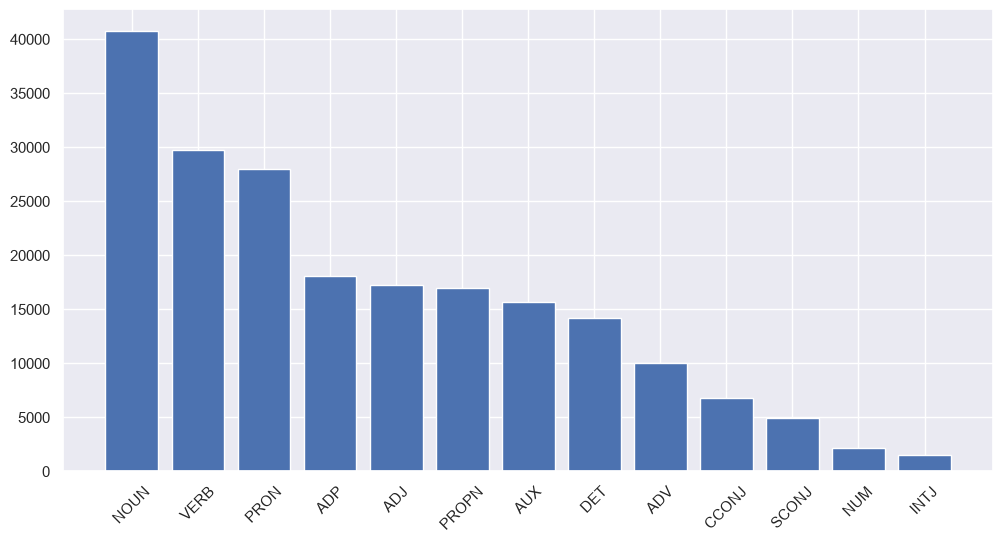

In [4]:
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

pos_freq = Counter(t.pos_ for doc in docs for t in doc if t.pos_ not in ('PUNCT', 'SYM', 'SPACE', 'X', 'PART'))
a = pos_freq.most_common(15)
x = [i[0] for i in a]
y = [i[1] for i in a]
plt.figure(figsize=(12, 6))
plt.bar(x, y)
plt.xticks(rotation=45)
pos_freq.most_common(10)

pos,NOUN,VERB,ADJ,PROPN,PRON,INTJ
cyberbullying_type,,,,,,
age,20.03,15.00,8.35,4.08,15.18,0.55
ethnicity,19.82,14.07,10.18,9.52,13.96,0.90
gender,22.05,13.87,9.00,6.81,12.46,0.80
not_cyberbullying,19.56,14.27,6.38,13.66,11.99,1.23
other_cyberbullying,18.31,15.75,6.39,6.98,15.43,1.22
religion,18.42,14.01,8.22,10.81,12.38,0.47


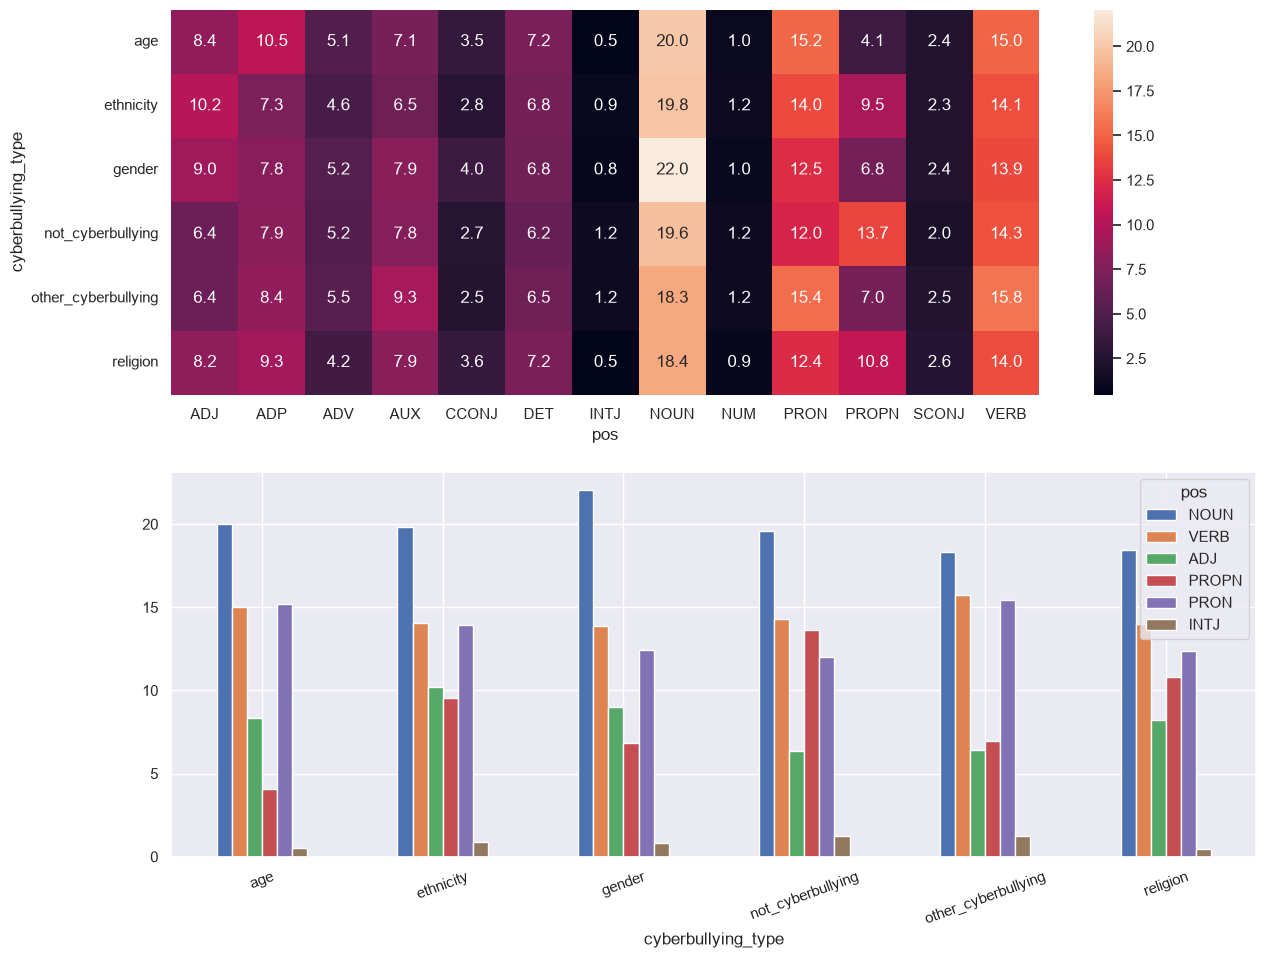

In [5]:
pos_df = pd.DataFrame(
    [(c, t.pos_) for c, doc in zip(sample[label], docs)
     for t in doc if t.pos_ not in ('PUNCT', 'SYM', 'SPACE', 'X', 'PART')],
    columns=[label, 'pos']
)
ct = pd.crosstab(pos_df[label], pos_df['pos'])
pct = ct.div(ct.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(2, 1, figsize=(14, 11))
sns.heatmap(pct, annot=True, fmt='.1f', ax=ax[0])
pct[['NOUN', 'VERB', 'ADJ', 'PROPN', 'PRON', 'INTJ']].plot(kind='bar', ax=ax[1])
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=20)
pct[['NOUN', 'VERB', 'ADJ', 'PROPN', 'PRON', 'INTJ']].round(2)

разница по классам (в % токенов класса):

- ADJ: ethnicity 10.2 / gender 9.0 > not_cyberbullying 6.4 — оскорбления строятся на прилагательных-характеристиках
  («dumb», «islamic», «white»), в нейтральных твитах прилагательных заметно меньше
- PROPN: not_cyberbullying 13.7 — максимум, разговоры про людей и телешоу; religion 10.8 / ethnicity 9.5 —
  имена, национальности, религии как непосредственные объекты упоминания
- INTJ: везде < 1.3%, минимум в religion 0.5 — «спорные» темы пишутся без междометий
- PRON + VERB выше всех в other_cyberbullying (15.4 / 15.8) — нарратив о действиях третьих лиц

### tagger errors

In [6]:
err_examples = [
    'Lolol that boy is whipped AF',
    'tbh rooting for jane and emma bc we have that lawyer bond',
    "ur bully's look official no homo lol",
    'Vicky and Celine will win this shit go girls!!!!!! I love YALL beat satan!!!',
]
for ex in err_examples:
    print([(t.text, t.pos_) for t in nlp(clean(ex))])

[('Lolol', 'PROPN'), ('that', 'DET'), ('boy', 'NOUN'), ('is', 'AUX'), ('whipped', 'VERB'), ('AF', 'PROPN')]
[('tbh', 'NOUN'), ('rooting', 'VERB'), ('for', 'ADP'), ('jane', 'NOUN'), ('and', 'CCONJ'), ('emma', 'PROPN'), ('bc', 'PROPN'), ('we', 'PRON'), ('have', 'VERB'), ('that', 'DET'), ('lawyer', 'NOUN'), ('bond', 'NOUN')]
[('ur', 'PROPN'), ('bully', 'PROPN'), ("'s", 'PART'), ('look', 'NOUN'), ('official', 'ADJ'), ('no', 'DET'), ('homo', 'NOUN'), ('lol', 'ADJ')]
[('Vicky', 'PROPN'), ('and', 'CCONJ'), ('Celine', 'PROPN'), ('will', 'AUX'), ('win', 'VERB'), ('this', 'DET'), ('shit', 'NOUN'), ('go', 'VERB'), ('girls', 'NOUN'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('I', 'PRON'), ('love', 'VERB'), ('YALL', 'PROPN'), ('beat', 'VERB'), ('satan', 'PROPN'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('!', 'PUNCT')]


5 ошибок тэггера из-за сленга/шума:

1. `AF` («as fuck», интенсификатор) -> PROPN, должно быть ADV
2. `tbh` («to be honest») -> NOUN, должно быть ADV
3. `ur` (= your) -> PROPN, должно быть PRON
4. `lol` -> ADJ в конце фразы (в начале фразы тот же токен получает NOUN) — должно быть INTJ,
   тег зависит от позиции, разметка сленга нестабильна
5. `YALL` (= you all) -> PROPN, должно быть PRON

закономерность: неизвестное сленговое слово модель по умолчанию считает именем собственным (PROPN) или
существительным — на таком тексте смещение по PROPN/NOUN в разметке гарантировано

## Syntax trees

In [7]:
from spacy import displacy

lens = sample[text].apply(lambda x: len(clean(x).split()))
mid = sample[lens.between(9, 15)].sample(10, random_state=1).index
for i in mid:
    print(docs[i].text)
    displacy.render(docs[i], style='dep', jupyter=True, options={'distance': 110})

Did you know 1 in 6 women is raped in her lifetime?


Where is your evidence that any of these people are Nazis, Putin troll.


I am not sexist. But i am becoming one when i am driving.


mkr Omg there restaurant looks like a a little girls room oh my! Gosh


Yes, we have heard it a million times. Islam is not about Islam.


All this means is that Muslims endlessly try to hide the barbarity of their religion.


As we said in my country: Fish dies for the mouth. See ya girls. mkr


: FUCK OBAMA, dumb ass nigger....you mad you oranga tang looking ass bitch?????


mkr kat and andre didn't vote fairly they don't deserve to win.


eggs and other things, which will unfortunately be the only part likely not open sourced.


## Patterns

In [8]:
def extract_pairs(doc):
    amod, subj = [], []
    for t in doc:
        if t.dep_ == 'amod' and t.head.pos_ in ('NOUN', 'PROPN'):
            amod.append((t.head.lemma_.lower(), t.lemma_.lower()))
        elif t.dep_ == 'nsubj' and t.pos_ in ('NOUN', 'PROPN') and t.head.pos_ == 'VERB':
            subj.append((t.lemma_.lower(), t.head.lemma_.lower()))
    return amod, subj

amod_pairs = Counter()
subj_pairs = Counter()
for doc in docs:
    a, s = extract_pairs(doc)
    amod_pairs.update(a)
    subj_pairs.update(s)
len(amod_pairs), len(subj_pairs)

(7213, 4180)

,pair,count
0,school high,834
1,nigger dumb,321
2,woman christian,156
3,terrorism islamic,141
4,school middle,122
5,fuck dumb,116
6,joke gay,107
7,people black,78
8,people white,56
9,ass dumb,45


,pair,count
0,girl bully,24
1,school bully,22
2,people have,17
3,cyrus make,17
4,girl go,16
5,people say,16
6,girl have,14
7,people call,14
8,people make,13
9,woman have,13


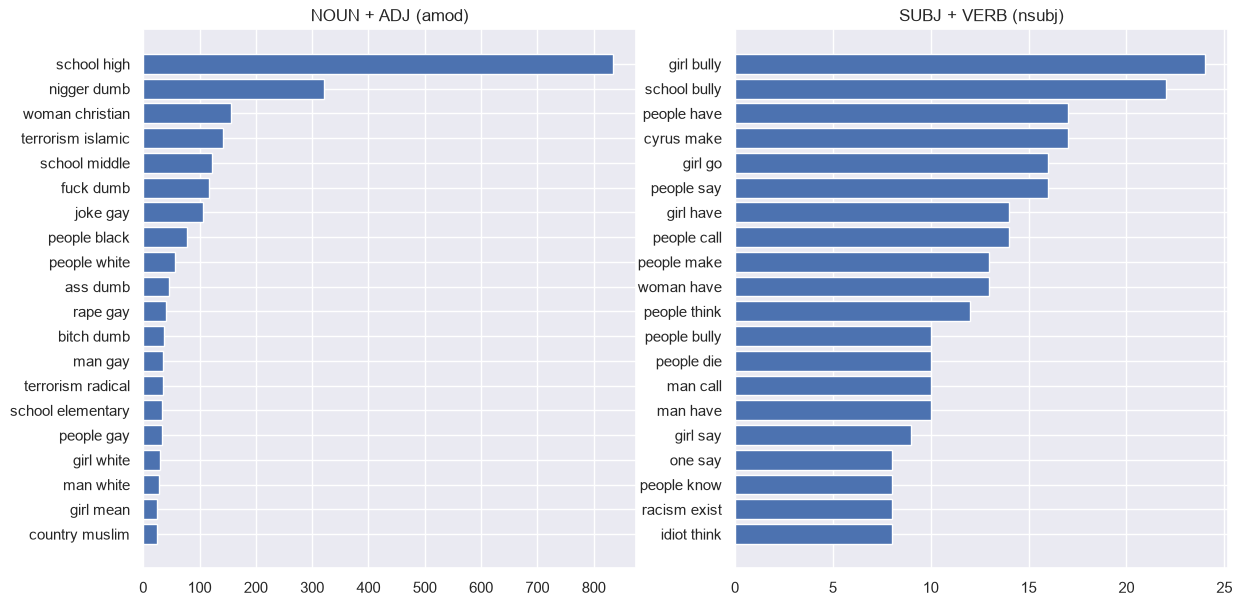

In [9]:
top_a = amod_pairs.most_common(20)
top_s = subj_pairs.most_common(20)
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].barh([' '.join(p) for p, c in top_a][::-1], [c for p, c in top_a][::-1])
ax[0].set_title('NOUN + ADJ (amod)')
ax[1].barh([' '.join(p) for p, c in top_s][::-1], [c for p, c in top_s][::-1])
ax[1].set_title('SUBJ + VERB (nsubj)')
display(pd.DataFrame(top_a, columns=['pair', 'count']).assign(pair=lambda x: x['pair'].map(' '.join)))
pd.DataFrame(top_s, columns=['pair', 'count']).assign(pair=lambda x: x['pair'].map(' '.join))

топ-20 пар и что они говорят о корпусе:

- `(school, high)` 834 — самый частотный, но нейтральный: артефакт домена (high school), не тональность
- `(nigger, dumb)` 321, `(fuck, dumb)` 116, `(ass, dumb)` 45, `(bitch, dumb)` 37 — токсичные оценки,
  ядро классов age/gender/ethnicity; прилагательное dumb — универсальный оценочный маркер корпуса
- `(woman, christian)` 156, `(terrorism, islamic)` 141, `(terrorism, radical)` 35 — класс religion
- `(people, black)` 78 / `(people, white)` 56 / `(people, gay)` 33 — класс ethnicity/gender
- субъект+действие: `(girl, bully)` 24, `(school, bully)` 22, `(people, ...)` — сама тема буллинга

вывод: пары достаточно точно отражают и тематику классов, и тональность (оскорбительное прилагательное +
уязвимая группа); исключение — коллокации домена вида high school, которые нужно фильтровать по стоп-листу

## Anaphora (rule-based)

In [10]:
PRONOUNS = {'he', 'she', 'they', 'it', 'him', 'her', 'them', 'his', 'their', 'hers', 'theirs', 'its'}

def antecedent(pron):
    # число из морфологии местоимения; род у англ. существительных не размечен, поэтому
    # согласование только по числу, при отсутствии числа принимаем кандидата
    num = pron.morph.get('Number')
    for cand in list(pron.doc)[:pron.i][::-1]:
        if cand.pos_ not in ('NOUN', 'PROPN'):
            continue
        cnum = cand.morph.get('Number')
        if num and cnum and num != cnum:
            continue
        return cand
    return None

def resolve_anaphora(doc):
    out = doc.text
    prons = [t for t in doc if t.lower_ in PRONOUNS and t.pos_ == 'PRON']
    for t in reversed(prons):  # с конца, чтобы не ломать idx более ранних токенов
        ant = antecedent(t)
        if ant is not None:
            out = out[:t.idx] + f'[{ant.text}]' + out[t.idx + len(t.text):]
    return out

In [11]:
shown = 0
for doc in docs:
    new = resolve_anaphora(doc)
    if new == doc.text:
        continue
    print(doc.text[:120])
    print('->', new[:130])
    print()
    shown += 1
    if shown == 8:
        break

that post ab kpop stans going to school together and everyone saying theyre gonna bully armys in the replies... and i'm 
-> that post ab kpop stans going to school together and everyone saying [stans]re gonna bully armys in the replies... and i'm suppose

Because some people have nothing better to do, or they were a bully in school and they never outgrew that
-> Because some people have nothing better to do, or [people] were a bully in school and [people] never outgrew that

These ladies really do remind me of the high school chicks...with all the bullying by one "Diva" and everyone stirring h
-> These ladies really do remind me of the high school chicks...with all the bullying by one "Diva" and everyone stirring [Diva] on..

... wilbur is 6'7... yeah most DEFINATLEY he would bully me in school
-> ... wilbur is 6'7... yeah most DEFINATLEY [wilbur] would bully me in school

I'm gonna name my kid jackin so in high school people bully him for his name sounding like jacking off
-> I'm gonn

алгоритм: местоимение 3-го лица -> ближайшее предшествующее существительное/имя с тем же числом
(морфология en_core_web_sm не размечает род у существительных, поэтому сравнение по роду
работает только косвенно — через число и одушевлённый контекст)

что видно на примерах:

- работает: `he ... [wilbur] would bully me`, `or [people] were a bully`, `[daughters] father's`
  — антецедент в той же фразе, число совпадает
- не работает: `people bully [school] for his name` — правильный антецедент `kid`, но `school` ближе;
  на «перескоках» через придаточные правило ближайшего существительного ошибается
- артефакт токенизации: `theyre` без апострофа бьётся на `they` + `re`, замена даёт `[stans]re` —
  сленг надо нормализовать ещё до разметки